# SF Airbnb Price Regression

**Goal:** predict the nightly `price` of San Francisco Airbnb listings (a **regression** task: predicting a continuous number).

**Dataset:** Kaggle "San Francisco Airbnb open data".

**Sections**
1. Setup
2. Load data
3. EDA
4. Cleaning
5. Feature engineering
6. Train/test split
7. Models
8. Evaluation & comparison
9. Conclusions

## 1. Setup

Here we import every library the notebook needs in one place, and define constants and folder paths. Keeping this in one cell means the rest of the notebook can rely on it, which is what makes **Restart & Run All** work.

We fix `RANDOM_STATE = 42`. A **random seed** makes anything random (train/test split, tree models) give the same result every run, so our results are reproducible.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
RANDOM_STATE = 42

# PyCharm may start the notebook with the working directory set to either the
# project root or notebooks/, so we find the project root in both cases.
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

RAW_DIR = PROJECT_ROOT / "data" / "raw"              # original Kaggle files, never modified
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"  # cleaned data we save ourselves
FIGURES_DIR = PROJECT_ROOT / "figures"               # plots for the report/presentation

# Consistent plot look across the whole notebook
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Project root:", PROJECT_ROOT)
print("Raw files found:", [p.name for p in RAW_DIR.glob("*")])

Project root: C:\Users\zaid2\PycharmProjects\AI_ML_PROJECT
Raw files found: ['listings.csv']


## 2. Load data

We read the raw listings file into a DataFrame called `df_raw`, then look at its **shape** (rows, columns), the first few rows, and the **dtypes** (data types). The dtypes matter because Airbnb files often store `price` as text like `"$1,250.00"`, which we will have to convert in the cleaning step.

We only *read* from `data/raw/`; we never write back to it.

> **Assumption:** the main file is called `listings.csv`. If the previous cell printed different file names, change `LISTINGS_FILE` below.

In [3]:
LISTINGS_FILE = "listings.csv"

# low_memory=False makes pandas read the whole file before guessing dtypes,
# which avoids mixed-type warnings on wide Airbnb files
df_raw = pd.read_csv(RAW_DIR / LISTINGS_FILE, low_memory=False)

print("Shape (rows, columns):", df_raw.shape)

Shape (rows, columns): (7535, 18)


In [4]:
df_raw.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,958,"Bright, Modern Garden Unit - 1BR/1BTH",1169,1462506189282101689,Holly,Western Addition,37.77028,-122.43317,Entire home/apt,291,2,507,15-11-2025,2.54,1,228,41,STR-0006854
1,5858,Creative Sanctuary,8904,1462506623299518225,Philip Jonathon,Bernal Heights,37.74474,-122.42089,Entire home/apt,322,30,105,06-08-2017,0.52,1,365,0,NaN
2,8142,*FriendlyRoom Apt. Style -UCSF/USF - San Franc...,21994,1462506956810615042,Aaron,Haight Ashbury,37.76555,-122.45213,Private room,125,32,10,30-07-2023,0.07,20,362,0,NaN
3,8339,Historic Alamo Square Victorian,24215,1462506994551169471,Rosmarie,Western Addition,37.77377,-122.43614,Entire home/apt,282,9,25,28-06-2019,0.13,1,339,0,STR-0000264
4,10537,Elegant & Cozy w/City views. Private room: Purple,36752,1462507288958203289,Teresa,Bayview,37.71750,-122.39698,Private room,108,1,46,07-11-2025,0.24,3,365,12,2022-011003STR


In [5]:
# Column names, dtypes and non-null counts in one view.
# "object" means text; we expect `price` to show up as object.
df_raw.info(max_cols=200)

<class 'pandas.DataFrame'>
RangeIndex: 7535 entries, 0 to 7534
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              7535 non-null   int64  
 1   name                            7535 non-null   str    
 2   host_id                         7535 non-null   int64  
 3   host_profile_id                 7535 non-null   int64  
 4   host_name                       7341 non-null   str    
 5   neighbourhood                   7535 non-null   str    
 6   latitude                        7535 non-null   float64
 7   longitude                       7535 non-null   float64
 8   room_type                       7535 non-null   str    
 9   price                           7535 non-null   int64  
 10  minimum_nights                  7535 non-null   int64  
 11  number_of_reviews               7535 non-null   int64  
 12  last_review                     5862 non-null

## 3. EDA (Exploratory Data Analysis)

**EDA** means *Exploratory Data Analysis*: looking at the data with tables and plots *before* modeling, to learn what it contains, what is broken or missing, and which columns might help predict `price`.

We will look at:
1. Missing values
2. The distribution of `price` (the target)
3. How `price` relates to room type, neighbourhood, reviews and location

We only *look* at `df_raw` here. Nothing is changed or dropped until Section 4.

In [6]:
# Which columns have missing values, and how many?
missing = df_raw.isna().sum()
missing_table = pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df_raw) * 100).round(1),
})
missing_table[missing_table["missing"] > 0].sort_values("missing", ascending=False)

,missing,percent
license,2637,35.0
last_review,1673,22.2
reviews_per_month,1673,22.2
host_name,194,2.6


In [7]:
# Summary statistics of the target. Percentiles show how extreme the top end is.
print(df_raw["price"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]))
print("\nListings with price == 0:", (df_raw["price"] == 0).sum())

count    7535.000000
mean      256.739615
std       109.302740
min        49.000000
1%         91.000000
25%       153.000000
50%       256.000000
75%       353.000000
95%       429.000000
99%       446.000000
max       449.000000
Name: price, dtype: float64

Listings with price == 0: 0


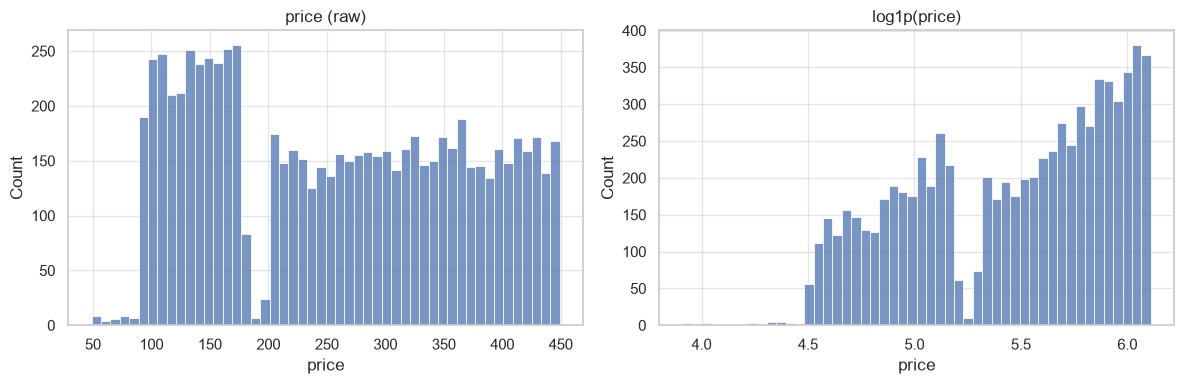

In [8]:
# Raw price vs log1p(price). If the raw plot has a long right tail, the data is
# **right-skewed** (a few very expensive listings drag the tail out), and the log
# transform should make it look closer to a bell shape.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_raw["price"], bins=50, ax=axes[0])
axes[0].set_title("price (raw)")

sns.histplot(np.log1p(df_raw["price"]), bins=50, ax=axes[1])
axes[1].set_title("log1p(price)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_price_distribution.png", dpi=150)
plt.show()

                 count  median   mean
room_type                            
Entire home/apt   4669   329.0  327.0
Hotel room         233   238.0  235.5
Private room      2599   135.0  134.8
Shared room         34    70.5   69.5


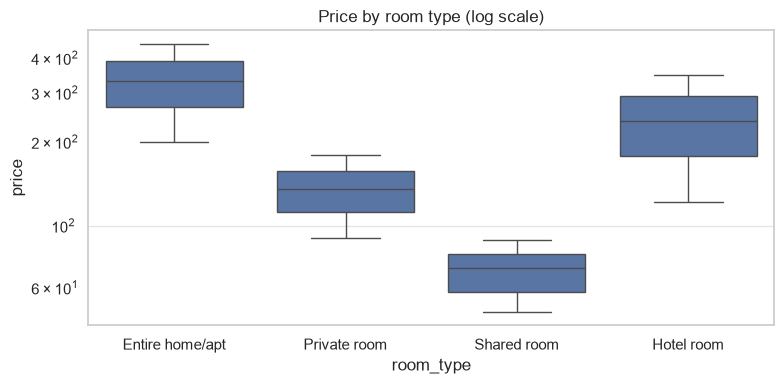

In [9]:
# Room type: how many listings of each kind, and what do they cost?
print(df_raw.groupby("room_type")["price"].agg(["count", "median", "mean"]).round(1))

# Log y-axis so the expensive outliers don't squash the boxes
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_raw, x="room_type", y="price")
plt.yscale("log")
plt.title("Price by room type (log scale)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_price_by_room_type.png", dpi=150)
plt.show()

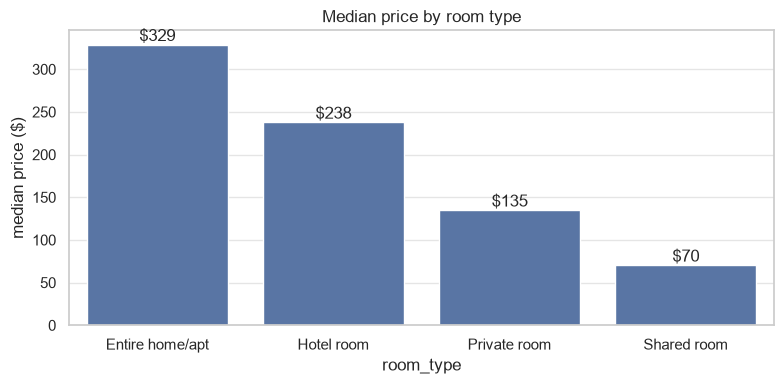

In [10]:
# Simple companion to the boxplot: one bar per room type showing the median price.
# The median is used (not the mean) so a few extreme listings don't distort it.
median_by_room = df_raw.groupby("room_type")["price"].median().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=median_by_room.index, y=median_by_room.values)
ax.bar_label(ax.containers[0], fmt="$%.0f")  # print the value on top of each bar
plt.ylabel("median price ($)")
plt.xlabel("room_type")
plt.title("Median price by room type")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_median_price_by_room_type.png", dpi=150)
plt.show()

In [11]:
# Neighbourhood: many categories, so compare median price (less sensitive to
# outliers than the mean). We ignore neighbourhoods with fewer than 20 listings
# because their medians are unreliable.
print("Number of neighbourhoods:", df_raw["neighbourhood"].nunique())

hood_stats = (
    df_raw.groupby("neighbourhood")["price"]
    .agg(["count", "median"])
    .query("count >= 20")
    .sort_values("median", ascending=False)
)
print("Neighbourhoods with >= 20 listings:", len(hood_stats))
pd.concat([hood_stats.head(5), hood_stats.tail(5)])

Number of neighbourhoods: 37
Neighbourhoods with >= 20 listings: 32


,count,median
neighbourhood,,
Presidio Heights,29,306.0
Noe Valley,239,297.0
Potrero Hill,140,293.0
Glen Park,50,290.5
Castro/Upper Market,294,288.5
Nob Hill,372,211.5
Bayview,151,211.0
Lakeshore,56,189.5
Excelsior,147,175.0


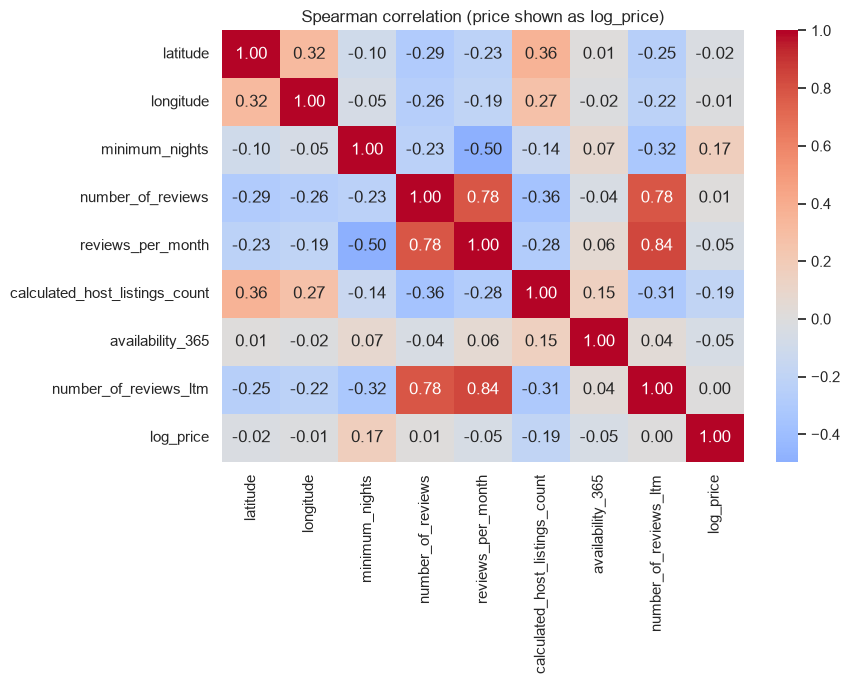

In [12]:
# Numeric features vs log price. We use **Spearman correlation** (compares rank
# order rather than exact values), which copes better with skewed data than the
# usual Pearson. IDs are left out because they are labels, not real measurements.
id_cols = ["id", "host_id", "host_profile_id"]
df_num = df_raw.select_dtypes(include="number").drop(columns=id_cols).copy()
df_num["log_price"] = np.log1p(df_num.pop("price"))

corr = df_num.corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation (price shown as log_price)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_correlation_heatmap.png", dpi=150)
plt.show()

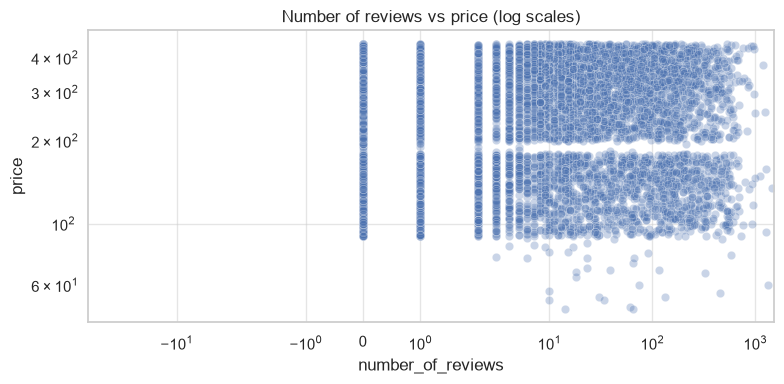

In [13]:
# Reviews vs price. log x-axis because review counts are also very skewed.
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_raw, x="number_of_reviews", y="price", alpha=0.3)
plt.xscale("symlog")
plt.yscale("log")
plt.title("Number of reviews vs price (log scales)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_reviews_vs_price.png", dpi=150)
plt.show()

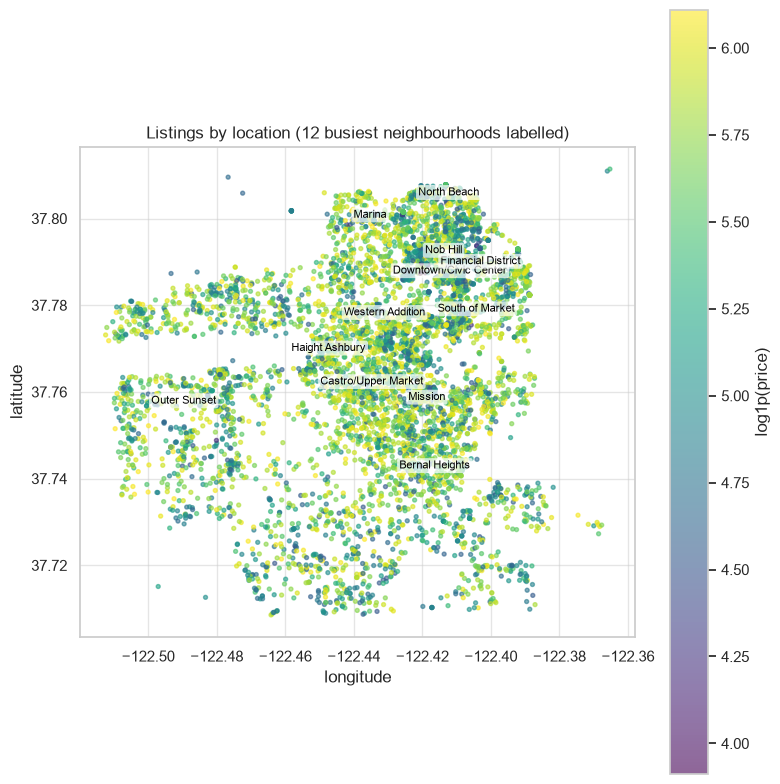

In [14]:
# Location: each dot is a listing, coloured by log price. Expensive areas should
# cluster in certain parts of the city.
# No basemap package is used, so we label the neighbourhoods with the most listings
# at the median position of their listings. That gives the dots some geography.
top_hoods = df_raw["neighbourhood"].value_counts().head(12).index
hood_centres = (
    df_raw[df_raw["neighbourhood"].isin(top_hoods)]
    .groupby("neighbourhood")[["longitude", "latitude"]]
    .median()
)

fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(
    df_raw["longitude"], df_raw["latitude"],
    c=np.log1p(df_raw["price"]), cmap="viridis", s=8, alpha=0.6,
)
plt.colorbar(sc, label="log1p(price)")

for name, row in hood_centres.iterrows():
    ax.annotate(
        name, (row["longitude"], row["latitude"]),
        fontsize=8, ha="center", color="black",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7),
    )

# One degree of longitude is shorter than one degree of latitude at SF's latitude,
# so we squash the x-axis a little to stop the city looking stretched sideways.
ax.set_aspect(1 / np.cos(np.radians(df_raw["latitude"].mean())))

ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Listings by location (12 busiest neighbourhoods labelled)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_price_map.png", dpi=150)
plt.show()

## 4. Cleaning

We build `df_clean` from a *copy* of `df_raw`, so the raw data is never touched. Steps:
1. Check for duplicate listings
2. Drop columns that are identifiers or free text (they can't help predict price)
3. Handle the missing values that come from listings with no reviews
4. Look for outliers

**Leakage note:** **data leakage** means information from the test set sneaking into training, which makes results look better than they really are. In this section we only apply fixed rules (e.g. "no reviews means 0 reviews per month"), not statistics learned from the data such as a mean or median. So it is safe to do before the train/test split. Any learned imputation (e.g. filling with the median) will wait for a `Pipeline` after the split.

Also: `price` is already a plain number in this file, so no text parsing is needed.

In [15]:
df_clean = df_raw.copy()  # work on a copy so df_raw stays untouched
print("Rows before cleaning:", len(df_clean))

# Each listing should appear once. If an id repeats, keep the first occurrence.
n_dup_ids = df_clean["id"].duplicated().sum()
df_clean = df_clean.drop_duplicates(subset="id")
print(f"Duplicate listing ids removed: {n_dup_ids}")
print("Rows after duplicate check:", len(df_clean))

Rows before cleaning: 7535
Duplicate listing ids removed: 0
Rows after duplicate check: 7535


In [16]:
# Columns we drop, and why. We print what is removed so nothing disappears silently.
cols_to_drop = {
    "id": "listing identifier, a label with no meaning for price",
    "host_id": "host identifier, a label (a model could memorise it instead of learning)",
    "host_profile_id": "host profile identifier, same reason as host_id",
    "name": "free-text listing title; we are not doing text processing",
    "host_name": "host's personal name, free text with no pricing meaning",
}

# Only drop columns that are still present, so re-running this cell does not crash.
# We print what was actually dropped, so nothing disappears silently.
to_drop_now = [col for col in cols_to_drop if col in df_clean.columns]
df_clean = df_clean.drop(columns=to_drop_now)
for col in to_drop_now:
    print(f"dropped {col}: {cols_to_drop[col]}")
if not to_drop_now:
    print("Nothing to drop: these columns were already removed.")
print("Columns left:", list(df_clean.columns))

# Note: `license` and `last_review` are kept for now. They have many missing values,
# but whether a listing HAS a licence, or how recent its last review is, might be
# useful features. We decide in Section 5 (feature engineering).

dropped id: listing identifier, a label with no meaning for price
dropped host_id: host identifier, a label (a model could memorise it instead of learning)
dropped host_profile_id: host profile identifier, same reason as host_id
dropped name: free-text listing title; we are not doing text processing
dropped host_name: host's personal name, free text with no pricing meaning
Columns left: ['neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'license']


In [17]:
# reviews_per_month is missing for 1,673 listings. Our guess: those are listings
# with zero reviews (nothing to average). Verify before filling anything.
no_reviews = df_clean["number_of_reviews"] == 0
missing_rpm = df_clean["reviews_per_month"].isna()

print("Listings with 0 reviews:", no_reviews.sum())
print("reviews_per_month missing:", missing_rpm.sum())
print("Missing AND 0 reviews:", (missing_rpm & no_reviews).sum())

Listings with 0 reviews: 1673
reviews_per_month missing: 1673
Missing AND 0 reviews: 1673


In [18]:
# The assert stops the cell with an error if our guess is wrong, so we never
# fill values on a false assumption.
assert (df_clean.loc[missing_rpm, "number_of_reviews"] == 0).all(), \
    "Some listings with reviews have a missing reviews_per_month"

# A listing with no reviews has 0 reviews per month, so 0 is the honest value.
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)

print(f"reviews_per_month: filled {missing_rpm.sum()} missing values with 0")
print("\nMissing values left:")
print(df_clean.isna().sum()[lambda s: s > 0])

reviews_per_month: filled 1673 missing values with 0

Missing values left:
last_review    1673
license        2637
dtype: int64


In [19]:
# Outlier check. We only LOOK here; no rows are removed in this cell.
# Price runs from 49 to 449 (seen in EDA), so the interesting columns are the others.
check_cols = ["price", "minimum_nights", "availability_365",
              "number_of_reviews", "calculated_host_listings_count"]
print(df_clean[check_cols].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).round(1))

print("\nminimum_nights > 365:", (df_clean["minimum_nights"] > 365).sum())
print("minimum_nights > 30:", (df_clean["minimum_nights"] > 30).sum())

        price  minimum_nights  availability_365  number_of_reviews  \
count  7535.0          7535.0            7535.0             7535.0   
mean    256.7            20.5             188.1               56.3   
std     109.3            49.3             133.9              118.9   
min      49.0             1.0               0.0                0.0   
1%       91.0             1.0               0.0                0.0   
50%     256.0             3.0             206.0                8.0   
95%     429.0            31.0             364.0              290.0   
99%     446.0           365.0             365.0              561.0   
max     449.0          1125.0             365.0             1447.0   

       calculated_host_listings_count  
count                          7535.0  
mean                             15.5  
std                              34.2  
min                               1.0  
1%                                1.0  
50%                               3.0  
95%                

In [20]:
# Does having a licence relate to price? We only LOOK here: df_clean is not changed.
has_license = df_clean["license"].notna().rename("has_license")

print("Overall:")
print(df_clean.groupby(has_license)["price"].agg(["count", "median", "mean"]).round(1))

# Licence status could just be a stand-in for room type (e.g. entire homes may be
# licensed more often), so we repeat the comparison inside each room type.
print("\nBy room type:")
print(df_clean.groupby(["room_type", has_license])["price"].agg(["count", "median"]).round(1))

Overall:
             count  median   mean
has_license                      
False         2637   280.0  272.5
True          4898   242.0  248.3

By room type:
                             count  median
room_type       has_license               
Entire home/apt False         1863   335.0
                True          2806   326.0
Hotel room      False            4   308.0
                True           229   234.0
Private room    False          768   135.0
                True          1831   136.0
Shared room     False            2    66.0
                True            32    73.5


### Decision: drop `license`

We tested whether having a licence relates to price (cell above) before dropping the column.

| | Licensed | Not licensed |
|---|---|---|
| Median price, all listings | $242 | $280 |
| Median price, entire homes | $326 | $335 |
| Median price, private rooms | $136 | $135 |

**Finding:** unlicensed listings look about $38 more expensive overall, but the gap almost disappears inside each room type (about $9 for entire homes, none for private rooms). The overall gap comes from a **mix effect** (a difference in the make-up of the two groups): 71% of unlicensed listings are entire homes versus 57% of licensed ones, and entire homes cost far more than private rooms. So licence status mostly repeats information already in `room_type`.

The hotel and shared-room gaps are not reliable because the unlicensed groups have only 4 and 2 listings.

**Why we drop it:**
- The raw values are registration codes, which are effectively identifiers, so they cannot be used as text.
- The yes/no version (`has_license`) adds almost nothing beyond `room_type`, and a feature that adds little makes the model harder to explain.
- It is also missing for 35% of listings.

If the models underperform later, we can revisit a `has_license` feature.

In [21]:
# Drop license now that the comparison above is done (the comparison cell needs it,
# so this cell must come after it). Safe to re-run: it only drops if still present.
if "license" in df_clean.columns:
    df_clean = df_clean.drop(columns="license")
    print("dropped license: codes are identifiers; has_license adds little beyond room_type")
else:
    print("Nothing to drop: license was already removed.")

print("Shape now:", df_clean.shape)
print("Columns left:", list(df_clean.columns))

dropped license: codes are identifiers; has_license adds little beyond room_type
Shape now: (7535, 12)
Columns left: ['neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm']


### Decision: outliers

From the outlier check above:

| Column | What we saw | Decision |
|---|---|---|
| `price` | range $49 to $449, no zeros, mean about equal to median | keep everything (looks capped already, no extreme tail) |
| `minimum_nights` | median 3, 95th percentile 31, 99th percentile 365, max 1125; only 5 listings above 365 | **cap at 365** |
| `calculated_host_listings_count` | max 194 | keep (large hosts with many listings are real) |
| `number_of_reviews` | max 1447 | keep (very popular listings are real) |

**Why cap `minimum_nights` and not remove rows:** 569 listings (about 8%) require more than 30 nights. These are genuine monthly rentals, so they stay. But a minimum stay of 1125 nights (over 3 years) is not realistic and is probably a data-entry mistake or a placeholder. To stop 5 extreme values from distorting models that are sensitive to scale (such as linear regression), we **cap** (clip) them at 365 instead of deleting those listings. Capping keeps all 7,535 rows. It is also a fixed rule, not something learned from the data, so it causes no leakage.

In [22]:
cap = 365
n_capped = (df_clean["minimum_nights"] > cap).sum()
df_clean["minimum_nights"] = df_clean["minimum_nights"].clip(upper=cap)

print(f"minimum_nights: capped {n_capped} listings at {cap} nights (no rows removed)")
print("Rows:", len(df_clean))
print(df_clean["minimum_nights"].describe().round(1))

minimum_nights: capped 5 listings at 365 nights (no rows removed)
Rows: 7535
count    7535.0
mean       20.2
std        46.1
min         1.0
25%         1.0
50%         3.0
75%        30.0
max       365.0
Name: minimum_nights, dtype: float64


In [23]:
# Save the cleaned data so later work can start from it. Raw data is never overwritten.
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
clean_path = PROCESSED_DIR / "listings_clean.csv"
df_clean.to_csv(clean_path, index=False)

print("Saved:", clean_path)
print("Shape:", df_clean.shape)
print("\nMissing values left:")
print(df_clean.isna().sum()[lambda s: s > 0])

Saved: C:\Users\zaid2\PycharmProjects\AI_ML_PROJECT\data\processed\listings_clean.csv
Shape: (7535, 12)

Missing values left:
last_review    1673
dtype: int64


## 5. Feature engineering

**Feature engineering** means creating new columns (features) from existing ones so a model can use the information more easily. We build `df_features` from a copy of `df_clean`, so re-running the cells is safe.

We create three features:
1. `days_since_last_review` and `has_reviews`, from the `last_review` date. A model cannot use a date written as text, but "how long ago" is a number it can use.
2. `distance_to_downtown_km`: distance from each listing to Union Square, built from latitude and longitude. The map in EDA showed price varies by location, and this gives the models one clear number for it.
3. `is_multi_host`: whether the host has more than one listing, which separates casual hosts from commercial ones.

**What we deliberately do NOT do here:** encoding categories (`neighbourhood`, `room_type`) and selecting features. **One-hot encoding** turns each category into its own 0/1 column, and it must learn the list of categories from the *training* data only. Feature selection also learns from data. Both would leak test information if done before the split, so they happen in a `Pipeline` in Sections 6 and 7. Every feature below uses a fixed rule, with nothing learned from the data, so creating them before the split is safe.

In [24]:
df_features = df_clean.copy()  # copy so this cell can be re-run safely

# A fixed reference date (not the newest date in the data, which would be a number
# learned from the data). Our latest review is 2025-12-07, so this is just after it.
REFERENCE_DATE = pd.Timestamp("2025-12-31")

# Dates are written day-month-year (e.g. 15-11-2025). An explicit format makes
# pandas raise an error if any value does not match, instead of guessing.
last_review_date = pd.to_datetime(df_features["last_review"], format="%d-%m-%Y")

df_features["days_since_last_review"] = (REFERENCE_DATE - last_review_date).dt.days
# Listings that were never reviewed have no date, so days stays missing for them.
# This flag tells the model which ones those are. The missing days are filled
# later inside the Pipeline, using only the training set.
df_features["has_reviews"] = df_features["last_review"].notna().astype(int)

# The raw date text is replaced by the numeric versions above
df_features = df_features.drop(columns="last_review")

print("has_reviews counts:")
print(df_features["has_reviews"].value_counts())
print("\nMissing days_since_last_review:", df_features["days_since_last_review"].isna().sum())
print(df_features["days_since_last_review"].describe().round(0))

# Sanity checks: no review should be dated after the reference date, and the
# listings without a date should be exactly the ones with 0 reviews.
assert (df_features["days_since_last_review"].dropna() >= 0).all()
assert (df_features["has_reviews"] == (df_features["number_of_reviews"] > 0)).all()

has_reviews counts:
has_reviews
1    5862
0    1673
Name: count, dtype: int64

Missing days_since_last_review: 1673
count    5862.0
mean      370.0
std       662.0
min        24.0
25%        47.0
50%        93.0
75%       323.0
max      5336.0
Name: days_since_last_review, dtype: float64


In [25]:
# Union Square, roughly the centre of downtown SF (fixed point chosen by us)
DOWNTOWN_LAT, DOWNTOWN_LON = 37.7880, -122.4075


def haversine_km(lat1, lon1, lat2, lon2):
    """Straight-line distance over the Earth's surface in km (the haversine formula).
    We need this because a degree of longitude is shorter than a degree of latitude,
    so plain subtraction of coordinates would not give true distances."""
    earth_radius_km = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * earth_radius_km * np.arcsin(np.sqrt(a))


df_features["distance_to_downtown_km"] = haversine_km(
    df_features["latitude"], df_features["longitude"], DOWNTOWN_LAT, DOWNTOWN_LON
)

print(df_features["distance_to_downtown_km"].describe().round(2))
# Does distance relate to price? Spearman again (rank-based, robust to skew).
corr_dist = df_features["distance_to_downtown_km"].corr(df_features["price"], method="spearman")
print("\nSpearman correlation with price:", round(corr_dist, 3))

count    7535.00
mean        3.54
std         2.70
min         0.03
25%         1.30
50%         2.98
75%         5.35
max        11.30
Name: distance_to_downtown_km, dtype: float64

Spearman correlation with price: 0.045


In [26]:
# 1 if the host has more than one listing, else 0
df_features["is_multi_host"] = (df_features["calculated_host_listings_count"] > 1).astype(int)

print(df_features["is_multi_host"].value_counts())
print("\nMedian price by group:")
print(df_features.groupby("is_multi_host")["price"].median())

is_multi_host
1    4824
0    2711
Name: count, dtype: int64

Median price by group:
is_multi_host
0    301.0
1    214.0
Name: price, dtype: float64


In [27]:
    # Final look at the feature table before we split the data
print("Shape:", df_features.shape)
print("\nMissing values left:")
print(df_features.isna().sum()[lambda s: s > 0])
print()
df_features.dtypes.to_frame("dtype").T

Shape: (7535, 15)

Missing values left:
days_since_last_review    1673
dtype: int64



,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,days_since_last_review,has_reviews,distance_to_downtown_km,is_multi_host
dtype,str,float64,float64,str,int64,int64,int64,float64,int64,int64,int64,float64,int64,float64,int64


## 6. Train/test split

We split the data into two parts:
- **Training set (80%)**: the models learn from this.
- **Test set (20%)**: kept locked away and used once at the end to measure how the models do on listings they have never seen. Using it for tuning would make our results look better than they really are.

**Why the split happens now:** this is the last step before anything is *fitted* to the data. From here on, imputers, encoders, scalers and models learn only from `X_train`, then are applied to `X_test`. That is what prevents **data leakage**.

Two choices:
- `X` holds the features and `y` holds the target `price`. We keep `price` in dollars. EDA showed it is not heavily skewed (mean about equal to median, capped at $449), so a log transform is not obviously needed. We can still test one later with cross-validation on the training set.
- We **stratify** by `room_type`, meaning the split keeps the same share of each room type in both sets. Without it, rare types (only 34 shared rooms in total) could land almost entirely in one set by bad luck.

In [28]:
X = df_features.drop(columns="price")  # features
y = df_features["price"]                # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,   # same split every run
    stratify=X["room_type"],     # keep room-type proportions equal in both sets
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print(f"Train share: {len(X_train) / len(X):.1%} | Test share: {len(X_test) / len(X):.1%}")

X_train: (6028, 14) | X_test: (1507, 14)
y_train: (6028,) | y_test: (1507,)
Train share: 80.0% | Test share: 20.0%


In [29]:
# Sanity check: the two sets should look alike, otherwise the test score would not
# be a fair estimate of how the model does on new listings.
print("Price (train) vs price (test):")
print(pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(1))

print("\nRoom type share:")
room_share = pd.DataFrame({
    "train": X_train["room_type"].value_counts(normalize=True),
    "test": X_test["room_type"].value_counts(normalize=True),
}).round(3)
print(room_share)

Price (train) vs price (test):
        train    test
count  6028.0  1507.0
mean    257.0   255.7
std     109.3   109.5
min      49.0    53.0
25%     153.0   152.0
50%     257.0   254.0
75%     353.0   353.0
max     449.0   449.0

Room type share:
                 train   test
room_type                    
Entire home/apt  0.620  0.620
Private room     0.345  0.345
Hotel room       0.031  0.031
Shared room      0.004  0.005


## 7. Models

We train progressively better models and compare them, always starting with simple baselines.

**Part 1 (this part):** preprocessing, baselines, then Linear Regression, Ridge and Lasso. Tree-based models come next.

Key ideas:
- **Baseline:** a deliberately dumb model (always predict the same price). Any real model must beat it, otherwise it has learned nothing.
- **Pipeline:** chains preprocessing and the model into one object. When we fit it on training data, every step (filling missing values, scaling, encoding) learns only from the training data. That is how we avoid leakage.
- **Cross-validation (CV):** split the *training* set into 5 parts, train on 4 and score on the 1 left out, rotate through all 5, and average. It gives a fair score without touching the test set, so we use it to compare models and to tune settings.
- **Regularization:** a penalty that stops a model from fitting the training data too closely (**overfitting**: memorising noise instead of learning real patterns). **Ridge** shrinks all coefficients towards zero. **Lasso** can shrink some of them exactly to zero, which removes those features. The setting `alpha` controls how strong the penalty is.

We compare models using MAE, RMSE and R² from CV on the training set. The test set is used only once, in Section 8.

In [30]:
# Which columns are text (need encoding) and which are numbers
categorical_features = ["neighbourhood", "room_type"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

# Numbers: fill missing values with the median (the only missing column is
# days_since_last_review), then scale. **Scaling** puts all features on a similar
# range (mean 0, std 1) so that large-valued features such as availability_365 do
# not dominate small ones in linear models.
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Text categories: one-hot encode. handle_unknown="ignore" means a category that
# appears only in the test set becomes all zeros instead of crashing.
categorical_pipe = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'days_since_last_review', 'has_reviews', 'distance_to_downtown_km', 'is_multi_host']
Categorical features: ['neighbourhood', 'room_type']


In [31]:
# Same 5 folds for every model, so scores are comparable
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []  # one row per model


def evaluate_cv(name, model):
    """5-fold CV on the TRAINING set only. Scores are averaged over the folds."""
    mae = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error").mean()
    rmse = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
    r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2").mean()
    cv_results.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})
    print(f"{name}: MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")

In [32]:
# Baselines: ignore every feature and always predict one number.
# R2 of about 0 means "no better than predicting the average".
models = {}

models["Baseline (mean)"] = Pipeline([
    ("prep", preprocessor), ("model", DummyRegressor(strategy="mean")),
])
models["Baseline (median)"] = Pipeline([
    ("prep", preprocessor), ("model", DummyRegressor(strategy="median")),
])

for name in ["Baseline (mean)", "Baseline (median)"]:
    evaluate_cv(name, models[name])

Baseline (mean): MAE=96.21  RMSE=109.26  R2=-0.001
Baseline (median): MAE=96.23  RMSE=109.27  R2=-0.001


In [33]:
# Plain Linear Regression: first real model, no penalty
models["Linear Regression"] = Pipeline([
    ("prep", preprocessor), ("model", LinearRegression()),
])
evaluate_cv("Linear Regression", models["Linear Regression"])

Linear Regression: MAE=48.53  RMSE=60.27  R2=0.695


In [34]:
# Ridge and Lasso: try several penalty strengths (alpha) with CV on the training set
# and keep the best. The test set is not involved.
alphas = [0.01, 0.1, 1, 10, 100]

for name, estimator in [
    ("Ridge", Ridge(random_state=RANDOM_STATE)),
    ("Lasso", Lasso(random_state=RANDOM_STATE, max_iter=10000)),
]:
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    search = GridSearchCV(
        pipe, param_grid={"model__alpha": alphas},
        cv=cv, scoring="neg_mean_absolute_error",
    )
    search.fit(X_train, y_train)
    print(f"{name}: best alpha = {search.best_params_['model__alpha']}")

    models[name] = search.best_estimator_
    evaluate_cv(name, models[name])

Ridge: best alpha = 1
Ridge: MAE=48.52  RMSE=60.25  R2=0.696
Lasso: best alpha = 0.1
Lasso: MAE=48.42  RMSE=60.07  R2=0.697


In [35]:
# Models so far, ranked by CV MAE (lower is better)
pd.DataFrame(cv_results).set_index("model").sort_values("MAE").round(3)

,MAE,RMSE,R2
model,,,
Lasso,48.425,60.068,0.697
Ridge,48.520,60.248,0.696
Linear Regression,48.528,60.266,0.695
Baseline (mean),96.207,109.258,-0.001
Baseline (median),96.228,109.272,-0.001
